# Assignment 2: Module 1, Fuzzy Logic

---

## Practical 4: Fuzzy Relation between Two Fuzzy Sets

### Aim
To create and display a fuzzy relation between two fuzzy sets, and to compose two relations.

### Theory
For fuzzy sets $A$ on $X$ and $B$ on $Y$, the Cartesian product gives a fuzzy relation:

$$R(x, y) = \min(A(x), B(y))$$

Given a second relation $S$ between $Y$ and $Z$, the max-min composition is:

$$T(x, z) = \max_{y} \min(R(x, y), S(y, z))$$

### Implementation


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Fuzzy set A on X (for example "Small") and fuzzy set B on Y (for example "Fast")
X = ["x1", "x2", "x3"]
A = np.array([0.2, 0.8, 1.0])

Y = ["y1", "y2", "y3", "y4"]
B = np.array([0.4, 1.0, 0.6, 0.1])

# 2. Build the relation R = A x B with the min rule
R = np.minimum.outer(A, B)
print("Relation R(x, y):")
print(np.round(R, 2))


Relation R(x, y):
[[0.2 0.2 0.2 0.1]
 [0.4 0.8 0.6 0.1]
 [0.4 1.  0.6 0.1]]


In [2]:
# 3. Second relation S between Y and Z
Z = ["z1", "z2"]
S = np.array([
    [0.9, 0.2],
    [0.5, 0.7],
    [0.3, 1.0],
    [0.6, 0.4],
])

# 4. Max-min composition T = R o S
T = np.max(np.minimum(R[:, :, None], S[None, :, :]), axis=1)
print("Composition T(x, z):")
print(np.round(T, 2))


Composition T(x, z):
[[0.2 0.2]
 [0.5 0.7]
 [0.5 0.7]]


### Visualization


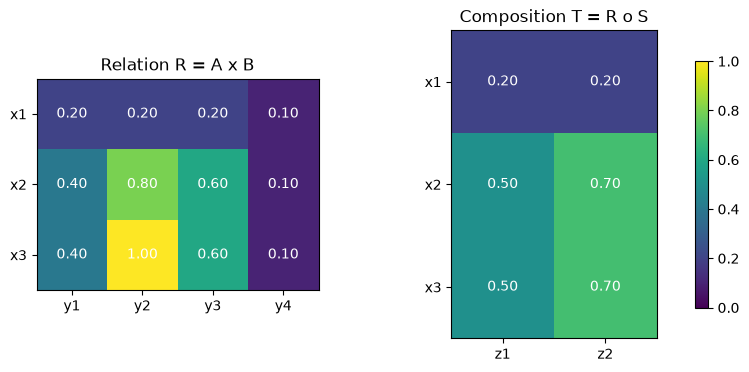

In [3]:
def show_heatmap(ax, M, row_labels, col_labels, title):
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(col_labels)))
    ax.set_xticklabels(col_labels)
    ax.set_yticks(range(len(row_labels)))
    ax.set_yticklabels(row_labels)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white")
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im = show_heatmap(axes[0], R, X, Y, "Relation R = A x B")
show_heatmap(axes[1], T, X, Z, "Composition T = R o S")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()


### Observation
- The largest value in $R$ is 1.00 at $(x_3, y_2)$, since both $A(x_3) = 1$ and $B(y_2) = 1$.
- The min rule means a pair is only as strong as its weaker member, for example $R(x_2, y_4) = 0.10$.
- In the composition, $T(x_2, z_2) = 0.70$ comes from $y_2$, where $\min(0.8, 0.7) = 0.7$ is the largest value.

### Conclusion
A fuzzy relation was built as a Cartesian product, a max-min composition was computed, and both were displayed as heatmaps.
